# 03 – Machine-learning model: day-ahead occupancy forecast

**Purpose:** build the main solution (report Section 3 *workflow* and Section 5 *validation*) and compare it with the two references from notebook 02.

**The forecasting situation.** At midnight before each day, forecast the mean headcount of every space for each of the next 24 hours, using **only what is known at midnight**: the calendar, and occupancy measured up to the end of the previous day. The HVAC is then scheduled ON for every hour forecast to have at least 1 person.

**Model:** gradient-boosted decision trees (scikit-learn `HistGradientBoostingRegressor`). Many small decision trees are built one after another, each correcting the errors of the ones before. Chosen because it handles non-linear patterns and interactions, works well on tabular data of this size, trains in about a second, and accepts missing inputs (sensor gaps) without inventing values.

**Procedure**
1. Build the model inputs.
2. Tune a few settings on the 2025 validation period (training on data before 2025).
3. Compare with the timetable and profile baseline on 2025.
4. Retrain on all data up to the end of 2025 and score **once** on the untouched 2026 test period.

In [1]:
import itertools
import pandas as pd
from occupancy import clean, evaluate, features, plots
from occupancy.models import GradientBoostingForecaster, ProfileBaseline, FixedTimetable
from occupancy.config import PROCESSED_DIR, FIGURES_DIR, REPO_ROOT

RESULTS = REPO_ROOT / "reports" / "results"; RESULTS.mkdir(exist_ok=True)
COLS = ["hours", "mae", "rmse", "correct_on", "wasted", "discomfort", "correct_off",
        "wasted_rate", "discomfort_rate", "accuracy"]

hourly = clean.load_hourly(PROCESSED_DIR / "occupancy_hourly.csv")
data = features.add_features(hourly)
split = evaluate.chronological_split(data)
train, val, test = split["train"], split["validation"], split["test"]
{k: len(v) for k, v in split.items()}

{'train': 29069, 'validation': 24759, 'test': 7160}

## 1. Model inputs
All inputs are known at midnight before the forecast day (see `src/occupancy/features.py`).

| Input | Meaning |
|---|---|
| `space` | which space |
| `hour_of_day`, `weekday_num`, `is_weekend` | calendar position |
| `in_semester` | 1 during Monash semester teaching weeks |
| `lag_1d` | headcount in the same hour **yesterday** |
| `lag_7d` | headcount in the same hour **last week** |
| `mean_4w` | average for the same weekday and hour over the **previous 4 weeks** |
| `yesterday_mean` | average headcount over **all of yesterday** |

Below: an example row, and the share of rows where each input is missing (because of sensor gaps).

In [2]:
example = data[(data["space"] == "G.25 MSM Lab") & (data["date"] == "2025-05-14") & (data["hour_of_day"] == 14)]
example[["date", "hour_of_day", "space", "mean_headcount"] + features.FEATURES[1:]].round(2)

,date,hour_of_day,space,mean_headcount,hour_of_day,weekday_num,is_weekend,in_semester,lag_1d,lag_7d,mean_4w,yesterday_mean
19174,2025-05-14,14,G.25 MSM Lab,3.5,14,2,0,1,0.69,0.78,1.48,1.4


In [3]:
data[features.FEATURES].isna().mean().rename("share missing").to_frame().style.format("{:.1%}")

,share missing
space,0.0%
hour_of_day,0.0%
weekday_num,0.0%
is_weekend,0.0%
in_semester,0.0%
lag_1d,14.8%
lag_7d,17.0%
mean_4w,4.0%
yesterday_mean,0.3%


### Leakage check
`lag_1d` for 14 May 2 pm must equal the *measured* value on 13 May 2 pm (and nothing from 14 May). The automated tests in `tests/test_features_ml.py` also confirm that changing a day's readings never changes that same day's inputs.

In [4]:
g25 = hourly[(hourly["space"] == "G.25 MSM Lab") & (hourly["hour_of_day"] == 14)].set_index("date")["mean_headcount"]
pd.Series({"lag_1d used for 14 May": example["lag_1d"].iloc[0], "measured 13 May": g25["2025-05-13"],
           "lag_7d used for 14 May": example["lag_7d"].iloc[0], "measured 7 May": g25["2025-05-07"]}).round(3)

lag_1d used for 14 May    0.689
measured 13 May           0.689
lag_7d used for 14 May    0.784
measured 7 May            0.784
dtype: float64

## 2. Tuning on the 2025 validation period
24 combinations of four settings, each trained on data before 2025 and scored on 2025:

* `learning_rate` – how strongly each new tree corrects the previous ones
* `max_leaf_nodes` – how complex each tree can be
* `min_samples_leaf` – minimum hours per leaf (stops the model memorising one-off events)
* `loss` – squared error, or Poisson (designed for non-negative counts)

The combination with the lowest validation MAE is kept.

In [5]:
grid = itertools.product([0.03, 0.1], [15, 31, 63], [20, 100], ["squared_error", "poisson"])
rows = []
for lr, leaves, min_leaf, loss in grid:
    params = dict(learning_rate=lr, max_leaf_nodes=leaves, min_samples_leaf=min_leaf, loss=loss)
    model = GradientBoostingForecaster(**params).fit(train)
    rows.append({**params, **evaluate.score_forecast(val, model.predict(val), "ML")})
tuning = pd.DataFrame(rows).sort_values("mae")
tuning.to_csv(RESULTS / "stage3_tuning.csv", index=False)
tuning[["learning_rate", "max_leaf_nodes", "min_samples_leaf", "loss", "mae", "rmse", "wasted", "discomfort", "accuracy"]].round(3).head(8)

,learning_rate,max_leaf_nodes,min_samples_leaf,loss,mae,rmse,wasted,discomfort,accuracy
5,0.03,31,20,poisson,0.595,1.243,3370,2065,0.780
1,0.03,15,20,poisson,0.596,1.238,3448,2027,0.779
3,0.03,15,100,poisson,0.597,1.242,3437,2023,0.779
13,0.10,15,20,poisson,0.599,1.255,3259,2147,0.782
9,0.03,63,20,poisson,0.599,1.254,3248,2182,0.781
7,0.03,31,100,poisson,0.601,1.250,3318,2101,0.781
0,0.03,15,20,squared_error,0.602,1.244,3637,1977,0.773
17,0.10,31,20,poisson,0.603,1.268,3132,2265,0.782


In [6]:
best = tuning.iloc[0][["learning_rate", "max_leaf_nodes", "min_samples_leaf", "loss"]].to_dict()
best["max_leaf_nodes"], best["min_samples_leaf"] = int(best["max_leaf_nodes"]), int(best["min_samples_leaf"])
print("Chosen settings:", best)
print(f"MAE range over all 24 settings: {tuning['mae'].min():.3f} – {tuning['mae'].max():.3f} people")

Chosen settings: {'learning_rate': 0.03, 'max_leaf_nodes': 31, 'min_samples_leaf': 20, 'loss': 'poisson'}
MAE range over all 24 settings: 0.595 – 0.646 people


## 3. Comparison on the 2025 validation period
All three approaches learn only from data before 2025.

In [7]:
timetable = FixedTimetable(8, 20)
baseline = ProfileBaseline().fit(train)
ml = GradientBoostingForecaster(**best).fit(train)
val_pred = val.assign(baseline=baseline.predict(val), model=ml.predict(val), timetable=timetable.schedule(val))

validation = pd.DataFrame([
    evaluate.score_schedule(val, val_pred["timetable"], "Fixed timetable (8am–8pm weekdays)"),
    evaluate.score_forecast(val, val_pred["baseline"], "Profile baseline"),
    evaluate.score_forecast(val, val_pred["model"], "Gradient boosting (ML)"),
]).set_index("approach")[COLS]
validation.to_csv(RESULTS / "stage3_validation.csv")
validation.round(3)

,hours,mae,rmse,correct_on,wasted,discomfort,correct_off,wasted_rate,discomfort_rate,accuracy
approach,,,,,,,,,,
Fixed timetable (8am–8pm weekdays),24759,NaN,NaN,8519,3339,2807,10094,0.249,0.248,0.752
Profile baseline,24759,0.753,1.368,9505,4927,1821,8506,0.367,0.161,0.727
Gradient boosting (ML),24759,0.595,1.243,9261,3370,2065,10063,0.251,0.182,0.780


### By space (2025)

In [8]:
def by_space(df_pred):
    rows = []
    for space, d in df_pred.groupby("space"):
        rows += [{"space": space, **evaluate.score_schedule(d, d["timetable"], "Timetable")},
                 {"space": space, **evaluate.score_forecast(d, d["baseline"], "Baseline")},
                 {"space": space, **evaluate.score_forecast(d, d["model"], "ML")}]
    return (pd.DataFrame(rows).pivot(index="space", columns="approach",
            values=["mae", "wasted_rate", "discomfort_rate", "accuracy"]).round(3))
by_space(val_pred)

mae                  wasted_rate                   \
approach      Baseline     ML Timetable    Baseline     ML Timetable   
space                                                                  
G.20 Breakout    1.346  1.111       NaN       0.699  0.522     0.367   
G.25 MSM Lab     0.789  0.530       NaN       0.343  0.211     0.245   
Space A          0.554  0.455       NaN       0.457  0.260     0.279   
Space B          0.466  0.423       NaN       0.138  0.158     0.162   

              discomfort_rate                  accuracy                   
approach             Baseline     ML Timetable Baseline     ML Timetable  
space                                                                     
G.20 Breakout           0.062  0.111     0.256    0.697  0.734     0.702  
G.25 MSM Lab            0.198  0.263     0.299    0.709  0.771     0.736  
Space A                 0.141  0.188     0.240    0.681  0.772     0.738  
Space B                 0.241  0.176     0.202    0.814  0.834     0.819

## 4. Which inputs matter? (Figure 5)
Permutation importance on 2025: each input is shuffled in turn and the rise in MAE is measured. Bigger rise = the model relies on it more.

,feature,mae_increase,std
1,hour_of_day,0.124,0.002
2,weekday_num,0.058,0.002
5,lag_1d,0.027,0.001
8,yesterday_mean,0.026,0.001
7,mean_4w,0.020,0.001
4,in_semester,0.016,0.001
6,lag_7d,0.012,0.000
0,space,0.005,0.001
3,is_weekend,-0.000,0.000


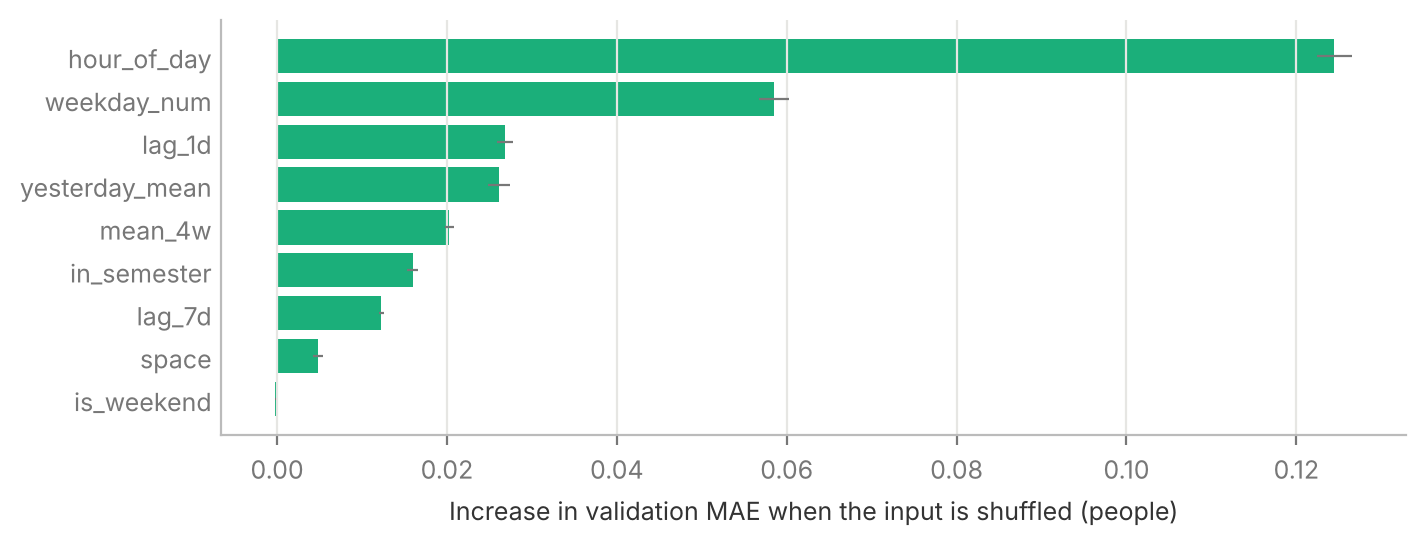

In [9]:
importance = ml.input_importance(val)
importance.to_csv(RESULTS / "stage3_input_importance.csv", index=False)
fig = plots.feature_importance(importance)
fig.savefig(FIGURES_DIR / "fig5_input_importance.png", facecolor="white")
importance.round(3)

## 5. Example week with the ML forecast (Figure 4, updated)

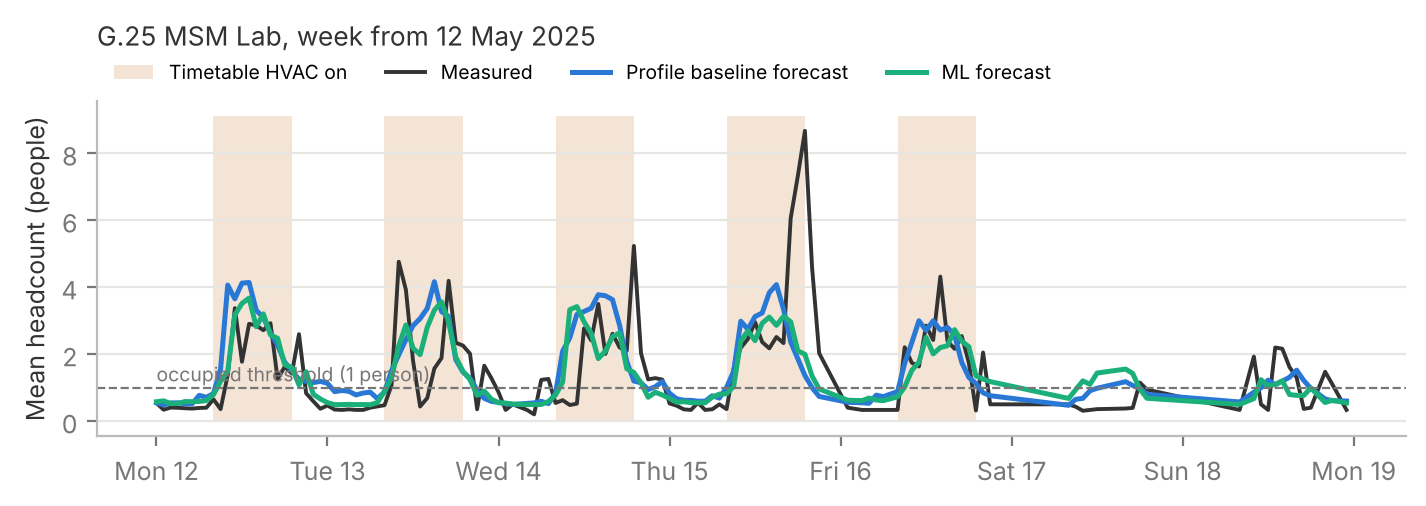

In [10]:
fig = plots.example_week(val_pred, space="G.25 MSM Lab", start="2025-05-12")
fig.savefig(FIGURES_DIR / "fig4_example_week.png", facecolor="white")

## 6. Final test: 1 Jan – 22 Apr 2026 (used once)
The baseline and ML model are retrained on **all data up to 31 Dec 2025** with the settings chosen above, then scored on 2026. Nothing was changed after seeing these results.

In [11]:
history = pd.concat([train, val])
baseline_final = ProfileBaseline().fit(history)
ml_final = GradientBoostingForecaster(**best).fit(history)
test_pred = test.assign(baseline=baseline_final.predict(test), model=ml_final.predict(test),
                        timetable=timetable.schedule(test))

final = pd.DataFrame([
    evaluate.score_schedule(test, test_pred["timetable"], "Fixed timetable (8am–8pm weekdays)"),
    evaluate.score_forecast(test, test_pred["baseline"], "Profile baseline"),
    evaluate.score_forecast(test, test_pred["model"], "Gradient boosting (ML)"),
]).set_index("approach")[COLS]
final.to_csv(RESULTS / "stage3_test.csv")
final.round(3)

,hours,mae,rmse,correct_on,wasted,discomfort,correct_off,wasted_rate,discomfort_rate,accuracy
approach,,,,,,,,,,
Fixed timetable (8am–8pm weekdays),7160,NaN,NaN,2591,1016,681,2872,0.261,0.208,0.763
Profile baseline,7160,0.678,1.381,2723,1259,549,2629,0.324,0.168,0.747
Gradient boosting (ML),7160,0.581,1.283,2621,836,651,3052,0.215,0.199,0.792


In [12]:
by_space(test_pred)

mae                  wasted_rate                   \
approach      Baseline     ML Timetable    Baseline     ML Timetable   
space                                                                  
G.20 Breakout    1.331  1.247       NaN       0.639  0.481     0.283   
G.25 MSM Lab     0.629  0.429       NaN       0.347  0.201     0.298   
Space A          0.494  0.451       NaN       0.322  0.243     0.342   
Space B          0.409  0.390       NaN       0.127  0.084     0.115   

              discomfort_rate                  accuracy                   
approach             Baseline     ML Timetable Baseline     ML Timetable  
space                                                                     
G.20 Breakout           0.046  0.079     0.170    0.754  0.786     0.792  
G.25 MSM Lab            0.322  0.437     0.378    0.660  0.730     0.678  
Space A                 0.148  0.179     0.151    0.761  0.788     0.749  
Space B                 0.188  0.156     0.164    0.842  0.880     0.861

## 7. Export every forecast
One row per space and hour for 2025 (validation) and 2026 (test): measured headcount, each forecast, each on/off decision and its outcome. Saved to `reports/results/forecasts_2025_2026.csv` so the results can be inspected or charted in Excel.

In [13]:
def outcome(on, occupied):
    return pd.Series(pd.NA, index=on.index, dtype="object").mask(on & occupied, "correct on") \
        .mask(on & ~occupied, "wasted").mask(~on & occupied, "discomfort").mask(~on & ~occupied, "correct off")

export = pd.concat([val_pred.assign(period="validation 2025"), test_pred.assign(period="test 2026")])
thr = evaluate.OCCUPIED_THRESHOLD
occupied = export["mean_headcount"] >= thr
export = pd.DataFrame({
    "period": export["period"], "hour_start": export["hour"].dt.strftime("%Y-%m-%d %H:%M"),
    "space": export["space"], "weekday": export["weekday"], "hour_of_day": export["hour_of_day"],
    "in_semester": export["in_semester"], "measured": export["mean_headcount"].round(3),
    "baseline_forecast": export["baseline"].round(3), "ml_forecast": export["model"].round(3),
    "occupied": occupied,
    "timetable_outcome": outcome(export["timetable"], occupied),
    "baseline_outcome": outcome(export["baseline"] >= thr, occupied),
    "ml_outcome": outcome(export["model"] >= thr, occupied),
})
export.to_csv(RESULTS / "forecasts_2025_2026.csv", index=False)
export.head()

,period,hour_start,space,weekday,hour_of_day,in_semester,measured,baseline_forecast,ml_forecast,occupied,timetable_outcome,baseline_outcome,ml_outcome
4230,validation 2025,2025-01-01 11:00,G.20 Breakout,Wednesday,11,0,0.361,2.921,0.912,False,wasted,wasted,correct off
4231,validation 2025,2025-01-01 12:00,G.20 Breakout,Wednesday,12,0,0.333,3.357,1.046,False,wasted,wasted,wasted
4232,validation 2025,2025-01-02 07:00,G.20 Breakout,Thursday,7,0,0.333,0.690,0.412,False,correct off,correct off,correct off
4233,validation 2025,2025-01-02 08:00,G.20 Breakout,Thursday,8,0,0.333,1.174,0.723,False,wasted,wasted,correct off
4234,validation 2025,2025-01-02 11:00,G.20 Breakout,Thursday,11,0,0.375,2.878,0.998,False,wasted,wasted,correct off


## 8. Observations
* **The ML model beats both references on both periods.** On 2025 validation its MAE is 0.595 people against 0.753 for the profile baseline (21% lower), and it makes the right HVAC decision in 78.0% of hours (baseline 72.7%, timetable 75.2%). On the untouched 2026 test it is again best: MAE 0.581 vs 0.678 (14% lower) and 79.2% correct (baseline 74.7%, timetable 76.3%).
* **Where the gain comes from.** Against the timetable, in 2025 the model conditions about the same number of empty hours (3,370 vs 3,339) but leaves 26% fewer occupied hours unconditioned (2,065 vs 2,807). In 2026 it wastes 18% fewer hours (836 vs 1,016) with slightly fewer discomfort hours (651 vs 681). The profile baseline still has the fewest discomfort hours, but only by conditioning far more empty hours.
* **The result is not sensitive to tuning.** All 24 settings gave a validation MAE between 0.595 and 0.646, all better than the baseline. The Poisson loss, designed for counts, was consistently a little better.
* **Inputs.** Hour of day and weekday matter most (the regular timetable pattern). The recent-occupancy inputs (yesterday's same hour, yesterday's average, the 4-week average) add the information that a fixed average cannot: whether *this* week is busier or quieter than usual. The semester flag also helps. `is_weekend` adds nothing because `weekday_num` already contains it, so it could be removed.
* **Limits.** G.20 Breakout remains the hardest space (MAE about 1.1–1.2 people) because it hosts irregular large gatherings. In G.25 the model misses more occupied hours in 2026 (discomfort rate 0.44) than the timetable (0.38); a lower switch-on threshold would trade some waste for comfort (tested in Stage 4). The test period is under four months (Jan–Apr 2026, one semester start), so the robustness checks in notebook 04 matter.
